# Fase C — Modelos predictivos: Presuntos homicidios en Colombia (2015–2024)

**Pregunta de negocio:** ¿se puede anticipar, con las características de la víctima, el lugar y el momento del hecho, si un homicidio será cometido con **arma de fuego**? Esto sirve para priorizar controles de porte de armas en los perfiles y zonas de mayor riesgo.

- **Problema supervisado:** clasificación binaria. Variable objetivo `es_arma_fuego` (1 = arma de fuego, 0 = otro mecanismo).
- **Modelos supervisados:** Regresión Logística, Árbol de Decisión y Random Forest.
- **Modelo no supervisado:** K-Means para segmentar municipios según su perfil de violencia.
- **Datos:** `datos_limpios.parquet` (salida de la Fase B).

## 1. Carga de datos

In [1]:
# ZANAHORIA_2026: librerías y carga del DataFrame limpio de la Fase B
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             silhouette_score, davies_bouldin_score)

zanahoria_2026_df = pd.read_parquet("datos_limpios.parquet")
print("Filas y columnas:", zanahoria_2026_df.shape)
print("\nVariable objetivo (es_arma_fuego):")
print(zanahoria_2026_df["es_arma_fuego"].value_counts())

Filas y columnas: (124914, 108)

Variable objetivo (es_arma_fuego):
es_arma_fuego
1    92662
0    32252
Name: count, dtype: int64


## 2. Variables de entrada y división train/test (80/20)
Se usa `stratify=y` para que entrenamiento y prueba tengan la misma proporción de arma de fuego (74,2 %).

In [2]:
# ZANAHORIA_2026: variables de entrada (X) y variable objetivo (y)
# Se usan las columnas numéricas/ordinales y las One-Hot (empiezan por "oh_")
columnas_numericas = ["Año del hecho", "grupo_edad_ord", "escolaridad_ord", "mes_num", "dia_num",
                      "homicidios_municipio_log"]
columnas_onehot = [c for c in zanahoria_2026_df.columns if c.startswith("oh_")]
columnas_x = columnas_numericas + columnas_onehot

X = zanahoria_2026_df[columnas_x]
y = zanahoria_2026_df["es_arma_fuego"]
print("Variables de entrada:", X.shape[1], f"({len(columnas_numericas)} numéricas + {len(columnas_onehot)} One-Hot)")

# División 80 % entrenamiento / 20 % prueba, manteniendo la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Entrenamiento: {len(X_train):,} filas | Prueba: {len(X_test):,} filas")
print(f"% arma de fuego en train: {y_train.mean()*100:.1f} % | en test: {y_test.mean()*100:.1f} %")

Variables de entrada: 84 (6 numéricas + 78 One-Hot)


Entrenamiento: 99,931 filas | Prueba: 24,983 filas
% arma de fuego en train: 74.2 % | en test: 74.2 %


## 3. Escalado después del split
El `StandardScaler` se ajusta (`fit`) **solo con X_train** y luego se aplica (`transform`) a X_test. Así el modelo nunca "ve" información del conjunto de prueba (sin *data leakage*). Las columnas One-Hot ya son 0/1 y no se escalan.

In [3]:
# ZANAHORIA_2026: escalar DESPUÉS del split (evita data leakage)
# El escalador aprende media y desviación SOLO con los datos de entrenamiento
escalador = StandardScaler()
X_train_esc = X_train.copy()
X_test_esc = X_test.copy()
X_train_esc[columnas_numericas] = escalador.fit_transform(X_train[columnas_numericas])
X_test_esc[columnas_numericas] = escalador.transform(X_test[columnas_numericas])

print("Media de las numéricas en train (debe ser ~0):")
print(X_train_esc[columnas_numericas].mean().round(3))
print("\nMedia de las numéricas en test (cercana a 0, pero no exacta):")
print(X_test_esc[columnas_numericas].mean().round(3))

Media de las numéricas en train (debe ser ~0):
Año del hecho               0.0
grupo_edad_ord              0.0
escolaridad_ord            -0.0
mes_num                    -0.0
dia_num                     0.0
homicidios_municipio_log   -0.0
dtype: float64

Media de las numéricas en test (cercana a 0, pero no exacta):
Año del hecho               0.003
grupo_edad_ord             -0.005
escolaridad_ord             0.001
mes_num                    -0.002
dia_num                    -0.006
homicidios_municipio_log    0.004
dtype: float64


## 4. Entrenamiento de los 3 modelos supervisados
Como el 74 % de los casos son arma de fuego, se usa `class_weight="balanced"`: sin esto, un modelo que siempre diga "arma de fuego" tendría 74 % de accuracy sin aprender nada. El árbol y el random forest tienen profundidad limitada para evitar sobreajuste.

In [4]:
# ZANAHORIA_2026: entrenar los 3 modelos supervisados
# class_weight="balanced" compensa que el 74 % de los casos sean arma de fuego
modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_leaf=20,
                                            class_weight="balanced", random_state=42, n_jobs=-1),
}

resultados = []
predicciones = {}
probabilidades = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_esc, y_train)
    y_pred = modelo.predict(X_test_esc)            # se evalúa en PRUEBA, no en entrenamiento
    y_prob = modelo.predict_proba(X_test_esc)[:, 1]
    predicciones[nombre] = y_pred
    probabilidades[nombre] = y_prob
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Accuracy train": accuracy_score(y_train, modelo.predict(X_train_esc)),
    })
    print(f"{nombre}: entrenado")

Regresión Logística: entrenado


Árbol de Decisión: entrenado


Random Forest: entrenado


## 5. Tabla comparativa de métricas (conjunto de prueba)

In [5]:
# ZANAHORIA_2026: tabla comparativa de métricas (conjunto de prueba)
zanahoria_2026_df_metricas = pd.DataFrame(resultados).set_index("Modelo").round(3)
zanahoria_2026_df_metricas.to_csv("zanahoria_2026_metricas_modelos.csv")
zanahoria_2026_df_metricas

,Accuracy,Precision,Recall,F1-score,F1 macro,ROC-AUC,Accuracy train
Modelo,,,,,,,
Regresión Logística,0.669,0.845,0.680,0.753,0.627,0.716,0.669
Árbol de Decisión,0.683,0.825,0.727,0.773,0.624,0.689,0.695
Random Forest,0.698,0.842,0.730,0.782,0.645,0.732,0.714


**Lectura de la tabla:**
- El **Random Forest** gana en 5 de las 6 métricas: accuracy 0,698, recall 0,730, F1 0,782, F1 macro 0,645 y ROC-AUC 0,732. Solo en precision la Regresión Logística queda apenas arriba (0,845 vs. 0,842).
- La accuracy (≈0,70) es menor que el 0,742 de un modelo que siempre dijera "arma de fuego", pero ese modelo trivial no detectaría **ningún** homicidio con otro mecanismo. Nuestros modelos detectan entre el 56 % y el 64 % de esos casos, por eso se comparan con **F1 y ROC-AUC**, no solo con accuracy.
- La diferencia entre accuracy de entrenamiento y de prueba es pequeña (máximo 1,6 puntos): **no hay sobreajuste**.

## 6. Visualizaciones de resultados

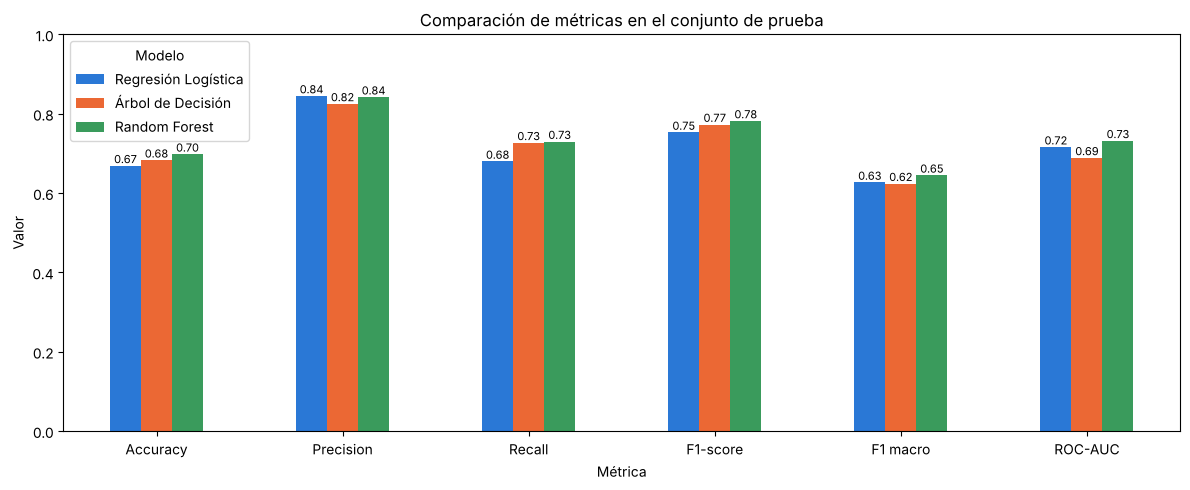

In [6]:
# ZANAHORIA_2026: gráfico de comparación de métricas
metricas_graf = ["Accuracy", "Precision", "Recall", "F1-score", "F1 macro", "ROC-AUC"]
ax = zanahoria_2026_df_metricas[metricas_graf].T.plot(kind="bar", figsize=(12, 5), rot=0,
                                                       color=["#2a78d6", "#eb6834", "#3a9b5c"])
ax.set_title("Comparación de métricas en el conjunto de prueba")
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.legend(title="Modelo")
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig("figuras/zanahoria_2026_comparacion_metricas.png", dpi=150)
plt.show()

**Insight:** los tres modelos tienen una precisión alta para arma de fuego (0,82–0,85): cuando predicen "arma de fuego", aciertan más de 8 de cada 10 veces. Random Forest tiene las mejores barras en casi todas las métricas.

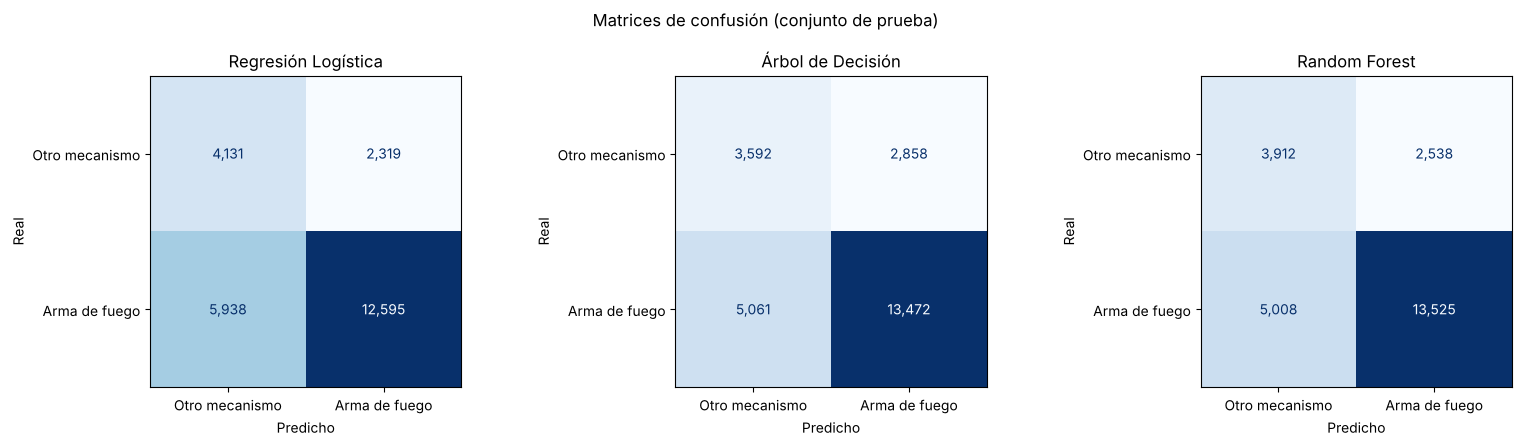

In [7]:
# ZANAHORIA_2026: matrices de confusión de los 3 modelos
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, nombre in enumerate(modelos):
    matriz = confusion_matrix(y_test, predicciones[nombre])
    ConfusionMatrixDisplay(matriz, display_labels=["Otro mecanismo", "Arma de fuego"]).plot(
        ax=axes[i], cmap="Blues", colorbar=False, values_format=",")
    axes[i].set_title(nombre)
    axes[i].set_xlabel("Predicho")
    axes[i].set_ylabel("Real")
plt.suptitle("Matrices de confusión (conjunto de prueba)")
plt.tight_layout()
plt.savefig("figuras/zanahoria_2026_matrices_confusion.png", dpi=150)
plt.show()

**Insight:** la clase "otro mecanismo" es la más difícil. El Random Forest acierta 3.912 de los 6.450 casos de otro mecanismo (61 %) y 13.525 de los 18.533 de arma de fuego (73 %). La Regresión Logística detecta un poco más de "otro mecanismo" (64 %), pero se equivoca más con arma de fuego.

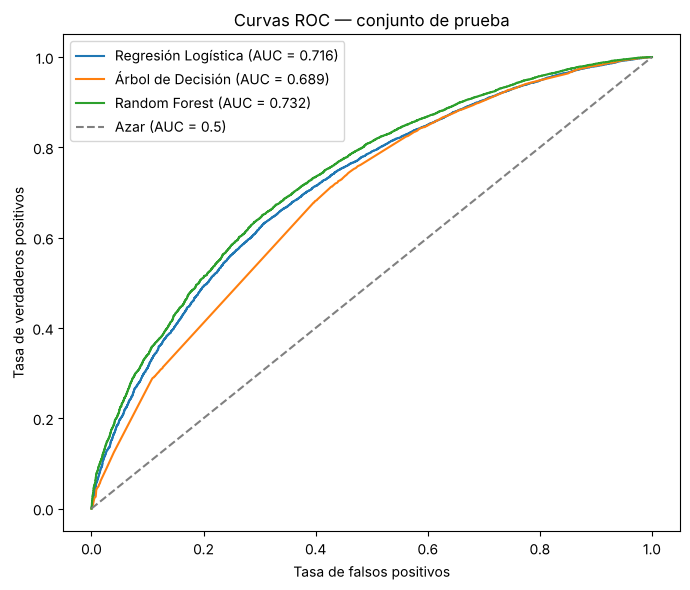

In [8]:
# ZANAHORIA_2026: curvas ROC
fig, ax = plt.subplots(figsize=(7, 6))
for nombre in modelos:
    fpr, tpr, _ = roc_curve(y_test, probabilidades[nombre])
    auc = zanahoria_2026_df_metricas.loc[nombre, "ROC-AUC"]
    ax.plot(fpr, tpr, label=f"{nombre} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Azar (AUC = 0.5)")
ax.set_title("Curvas ROC — conjunto de prueba")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/zanahoria_2026_curvas_roc.png", dpi=150)
plt.show()

**Insight:** todas las curvas están por encima de la diagonal del azar. El Random Forest tiene el mayor AUC (0,732): si se toma al azar un caso con arma de fuego y otro sin ella, el modelo le da mayor probabilidad al de arma de fuego el 73 % de las veces.

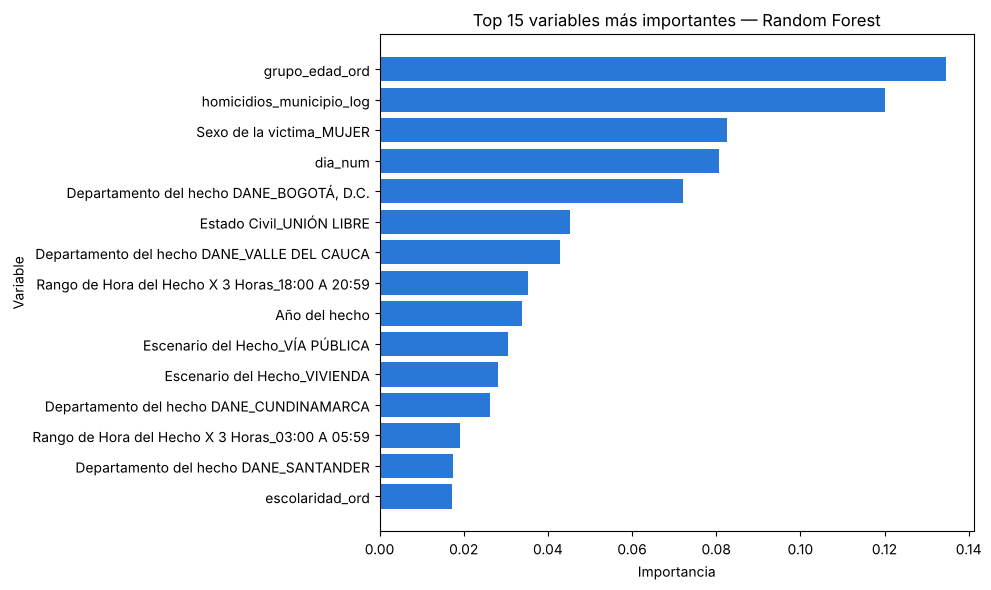

In [9]:
# ZANAHORIA_2026: variables más importantes según el Random Forest
importancias = pd.Series(modelos["Random Forest"].feature_importances_, index=columnas_x)
top15 = importancias.sort_values(ascending=False).head(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15.index.str.replace("oh_", ""), top15.values, color="#2a78d6")
ax.set_title("Top 15 variables más importantes — Random Forest")
ax.set_xlabel("Importancia")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.savefig("figuras/zanahoria_2026_importancia_variables.png", dpi=150)
plt.show()

**Insight:** las variables que más pesan son la **edad** (los jóvenes mueren más por arma de fuego), los **homicidios del municipio** (en las grandes ciudades domina el arma de fuego), el **sexo** (las mujeres mueren más por arma blanca o asfixia), el **día**, el **departamento** (Bogotá tiene más arma blanca; Valle más arma de fuego) y el escenario (vía pública vs. vivienda). Esto coincide con los hallazgos de la Fase A.

## 7. Modelo no supervisado — K-Means sobre municipios
Cada fila es un municipio con al menos 30 homicidios (464 municipios) y 5 variables: log de homicidios, % arma de fuego, % mujeres, % rural y edad promedio. Se escalan con `StandardScaler` porque K-Means usa distancias.

In [10]:
# ZANAHORIA_2026: tabla de municipios para el clustering (no supervisado)
# Solo municipios con al menos 30 homicidios, para que los porcentajes sean estables
zanahoria_2026_df["es_mujer"] = (zanahoria_2026_df["Sexo de la victima"] == "MUJER").astype(int)
zanahoria_2026_df["es_rural"] = (zanahoria_2026_df["Zona del Hecho"] == "PARTE RURAL(VEREDA Y CAMPO)").astype(int)

zanahoria_2026_df_mun = zanahoria_2026_df.groupby(["Código Dane Municipio", "Municipio del hecho DANE"]).agg(
    homicidios=("ID", "count"),
    pct_arma_fuego=("es_arma_fuego", "mean"),
    pct_mujeres=("es_mujer", "mean"),
    pct_rural=("es_rural", "mean"),
    edad_promedio=("edad_aprox", "mean"),
).reset_index()
zanahoria_2026_df_mun = zanahoria_2026_df_mun[zanahoria_2026_df_mun["homicidios"] >= 30].copy()
zanahoria_2026_df_mun["log_homicidios"] = np.log1p(zanahoria_2026_df_mun["homicidios"])
print("Municipios para el clustering:", len(zanahoria_2026_df_mun))

# Escalar las 5 variables (K-Means usa distancias, todas deben pesar igual)
columnas_cluster = ["log_homicidios", "pct_arma_fuego", "pct_mujeres", "pct_rural", "edad_promedio"]
X_cluster = StandardScaler().fit_transform(zanahoria_2026_df_mun[columnas_cluster])

Municipios para el clustering: 464


   k   Inercia  Silhouette  Davies-Bouldin
0  2  1784.149       0.211           1.657
1  3  1455.233       0.216           1.515
2  4  1260.068       0.219           1.399
3  5  1119.586       0.208           1.384
4  6  1006.261       0.208           1.312
5  7   931.211       0.199           1.382
6  8   871.192       0.198           1.358


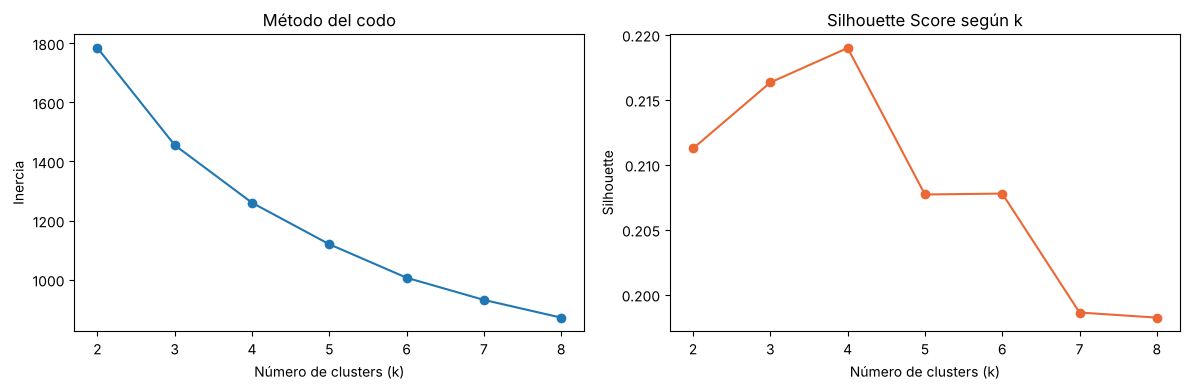

In [11]:
# ZANAHORIA_2026: elegir k con el método del codo y el Silhouette Score
valores_k = range(2, 9)
inercias = []
siluetas = []
davies = []
for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_cluster)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X_cluster, etiquetas))
    davies.append(davies_bouldin_score(X_cluster, etiquetas))

zanahoria_2026_df_k = pd.DataFrame({"k": list(valores_k), "Inercia": inercias,
                                    "Silhouette": siluetas, "Davies-Bouldin": davies}).round(3)
print(zanahoria_2026_df_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valores_k), inercias, marker="o")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")
axes[1].plot(list(valores_k), siluetas, marker="o", color="#eb6834")
axes[1].set_title("Silhouette Score según k")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig("figuras/zanahoria_2026_eleccion_k.png", dpi=150)
plt.show()

**Elección de k:** el Silhouette Score es máximo en **k = 4** (0,219) y el codo de la inercia se suaviza a partir de ahí. Davies-Bouldin sigue bajando un poco con más clusters, pero k = 4 da grupos que se pueden interpretar con claridad.

In [12]:
# ZANAHORIA_2026: K-Means final con el k elegido
k_final = 4
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
zanahoria_2026_df_mun["cluster"] = kmeans_final.fit_predict(X_cluster)

print(f"K-Means con k = {k_final}")
print(f"  Silhouette Score: {silhouette_score(X_cluster, zanahoria_2026_df_mun['cluster']):.3f}  (más alto es mejor, máx. 1)")
print(f"  Davies-Bouldin:   {davies_bouldin_score(X_cluster, zanahoria_2026_df_mun['cluster']):.3f}  (más bajo es mejor)")

# Perfil promedio de cada cluster
zanahoria_2026_df_perfil = zanahoria_2026_df_mun.groupby("cluster").agg(
    municipios=("homicidios", "count"),
    homicidios_total=("homicidios", "sum"),
    homicidios_mediana=("homicidios", "median"),
    pct_arma_fuego=("pct_arma_fuego", "mean"),
    pct_mujeres=("pct_mujeres", "mean"),
    pct_rural=("pct_rural", "mean"),
    edad_promedio=("edad_promedio", "mean"),
).round(2)
zanahoria_2026_df_perfil

K-Means con k = 4
  Silhouette Score: 0.219  (más alto es mejor, máx. 1)
  Davies-Bouldin:   1.399  (más bajo es mejor)


,municipios,homicidios_total,homicidios_mediana,pct_arma_fuego,pct_mujeres,pct_rural,edad_promedio
cluster,,,,,,,
0,122,85888,313.5,0.82,0.07,0.22,32.08
1,104,6795,50.0,0.70,0.12,0.56,36.97
2,60,10073,91.5,0.52,0.09,0.21,33.35
3,178,15609,72.0,0.80,0.06,0.57,33.78


**Métricas de clustering:** Silhouette 0,219 y Davies-Bouldin 1,40. Los grupos se solapan algo (es normal con datos sociales), pero tienen perfiles bien distintos.

In [13]:
# ZANAHORIA_2026: municipios de ejemplo de cada cluster (los de más homicidios)
for c in range(k_final):
    ejemplos = (zanahoria_2026_df_mun[zanahoria_2026_df_mun["cluster"] == c]
                .sort_values("homicidios", ascending=False)["Municipio del hecho DANE"].head(6).tolist())
    print(f"Cluster {c}: {', '.join(ejemplos)}")

Cluster 0: BOGOTÁ, D.C., CALI, MEDELLÍN, BARRANQUILLA, CARTAGENA DE INDIAS, CÚCUTA
Cluster 1: SAN VICENTE DEL CAGUÁN, PUERTO GAITÁN, SAN JOSÉ DEL GUAVIARE, DAGUA, SALGAR, CHAPARRAL
Cluster 2: BUCARAMANGA, IBAGUÉ, POPAYÁN, MANIZALES, PASTO, IPIALES
Cluster 3: ANDES, ITUANGO, EL TAMBO, ARAUQUITA, PUERTO GUZMÁN, SUÁREZ


**Interpretación de los 4 segmentos:**
| Cluster | Perfil | Ejemplos | Acción sugerida |
|---|---|---|---|
| 0 | **Grandes ciudades con arma de fuego**: muchos casos (mediana 314), 82 % arma de fuego, 22 % rural, víctimas jóvenes (32 años) | Bogotá, Cali, Medellín, Barranquilla, Cartagena, Cúcuta | Control de armas y prevención juvenil urbana |
| 1 | **Rural con más víctimas mujeres y mayores**: 56 % rural, 12 % mujeres, edad 37 años | San Vicente del Caguán, Puerto Gaitán, San José del Guaviare | Violencia intrafamiliar y presencia rural |
| 2 | **Ciudades intermedias con arma blanca**: solo 52 % arma de fuego, 21 % rural | Bucaramanga, Ibagué, Popayán, Manizales, Pasto | Riñas y arma cortopunzante (consumo de alcohol) |
| 3 | **Rural con arma de fuego**: 57 % rural, 80 % arma de fuego | Ituango, El Tambo, Arauquita, Puerto Guzmán, Suárez | Zonas con presencia de grupos armados |

El cluster 0 concentra 85.888 homicidios (73 % de los casos de estos municipios).

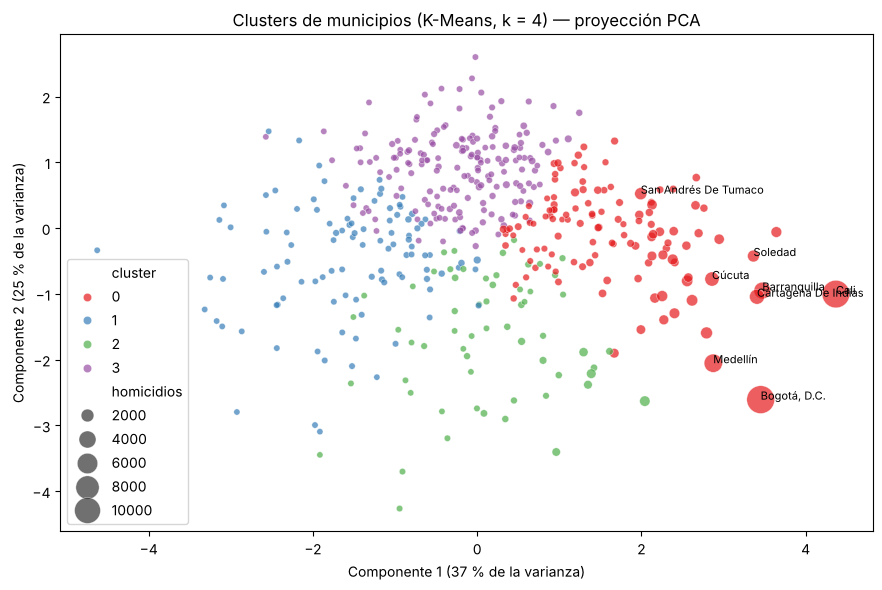

In [14]:
# ZANAHORIA_2026: visualizar los clusters en 2 dimensiones con PCA
pca = PCA(n_components=2, random_state=42)
componentes = pca.fit_transform(X_cluster)
zanahoria_2026_df_mun["pc1"] = componentes[:, 0]
zanahoria_2026_df_mun["pc2"] = componentes[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=zanahoria_2026_df_mun, x="pc1", y="pc2", hue="cluster", palette="Set1",
                size="homicidios", sizes=(20, 400), alpha=0.7, ax=ax)
# Nombres de las 8 ciudades con más homicidios
for _, fila in zanahoria_2026_df_mun.sort_values("homicidios", ascending=False).head(8).iterrows():
    ax.annotate(fila["Municipio del hecho DANE"].title(), (fila["pc1"], fila["pc2"]), fontsize=8)
ax.set_title(f"Clusters de municipios (K-Means, k = {k_final}) — proyección PCA")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]*100:.0f} % de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]*100:.0f} % de la varianza)")
plt.tight_layout()
plt.savefig("figuras/zanahoria_2026_clusters_pca.png", dpi=150)
plt.show()

**Insight:** en el plano PCA los clusters se separan principalmente por tamaño y nivel urbano (componente 1) y por mecanismo y sexo de las víctimas (componente 2). Las grandes ciudades quedan juntas en el cluster 0.

## 8. Modelo elegido y justificación
**Modelo final: Random Forest.**
1. **Precisión:** mejores resultados en 5 de las 6 métricas del conjunto de prueba (F1 0,782, F1 macro 0,645, AUC 0,732).
2. **Generalización:** solo 1,6 puntos de diferencia entre train y test, así que no está memorizando.
3. **Interpretabilidad:** aunque es menos simple que la Regresión Logística, entrega la importancia de cada variable, que se puede explicar en términos de negocio.

La **Regresión Logística** queda como alternativa si se necesita un modelo más simple y explicable: está a solo 1,6 puntos de AUC. El **Árbol de Decisión** es el más fácil de dibujar, pero es el más débil (AUC 0,689).

**Limitación:** un AUC de 0,73 indica un poder predictivo **moderado**. El dataset no tiene variables clave como el agresor o la circunstancia (más del 50 % de nulos), que serían las que más ayudarían.